## Lista 2
Karol Garbaczewski, Adam Freń

In [35]:
import numpy as np
import scipy.linalg
from operator import itemgetter
from useful_functions import gauss_solver
import cProfile 
import timeit
import matplotlib.pyplot as plt

### Zadanie 1
Rozwiąż (w pojedynczej precyzji) układ równań

$$A_{5×5}\overrightarrow{x} = \overrightarrow{b}$$
 
gdzie $A_{5×5}$ to macierz Hilberta i $\overrightarrow{b} = (5, 4, 3, 2, 1)^T$ . Skorzystaj z metody
iteracyjnego poprawiania rozwiązań.
#### Rozwiązanie z solverem numpy

In [2]:
n = 5
A = np.array([[1.0 / (i + j - 1) for j in range(1, n + 1)] for i in range(1, n + 1)], dtype=np.float32)
b = np.array([5.0, 4.0, 3.0, 2.0, 1.0], dtype=np.float32).transpose()

x = np.linalg.solve(A, b)
print("Rozwiązanie początkowe x^(1):\n", x)

k=0
while True:
    r = b.astype(np.float64) - np.linalg.matmul(A, x,).astype(np.float64)
    
    res_norm = np.max(np.abs(r))
    print(f"norma reszty = {res_norm}")
    
    if res_norm < 1e-7:  
        break
        
    dx = np.linalg.solve(A, r)
    
    x = x + dx
    k+=1

print("Ostateczne poprawione rozwiązanie:\n", x)

Rozwiązanie początkowe x^(1):
 [   -94.84782   2157.1013  -10697.322    17900.658    -9440.465  ]
norma reszty = 0.000244140625
norma reszty = 0.0001593655974136965
norma reszty = 5.444533712761768e-13
Ostateczne poprawione rozwiązanie:
 [   -94.84781941   2157.10127275 -10697.32231838  17900.65789663
  -9440.46525299]


#### Rozwiązanie z naszym solverem

In [3]:
n = 5
A = np.array([[1.0 / (i + j - 1) for j in range(1, n + 1)] for i in range(1, n + 1)], dtype=np.float32)
b = np.array([5.0, 4.0, 3.0, 2.0, 1.0], dtype=np.float32).transpose()

x = gauss_solver(A, b)
print("Rozwiązanie początkowe x^(1):\n", x)


for k in range(1_000_000):
    r = b.astype(np.float64) - np.linalg.matmul(A, x,).astype(np.float64)
    
    res_norm = np.max(np.abs(r))
    print(f"norma reszty = {res_norm}")
    
    if res_norm < 1e-7:  
        break
        
    dx = gauss_solver(A, r)
    
    x = x + dx

print("Ostateczne poprawione rozwiązanie:\n", x)

Rozwiązanie początkowe x^(1):
 [   -94.941315   2158.9722   -10705.703     17913.64      -9446.933   ]
norma reszty = 0.00048828125
norma reszty = 0.0001537872205186197
norma reszty = 1.042944266949064e-06
norma reszty = 7.686420389063642e-10
Ostateczne poprawione rozwiązanie:
 [   -94.84781954   2157.10127529 -10697.32232973  17900.65791418
  -9440.46526171]


### Zadanie 2
2. Napisz program rozwiązujący poniższy układ równań metodą Gaussa-
Seidla:
$$\begin{pmatrix}
4 & -1 & 0 & \cdots & 0 & 0 & 1 \\
-1 & 4 & -1 & \cdots & 0 & 0 & 0 \\
0 & -1 & 4 & \cdots & 0 & 0 & 0\\
\vdots & \vdots & \vdots & \ddots & \vdots & \vdots & \vdots \\
0 & 0 & 0 & \cdots & 4 & -1 & 0\\
0 & 0 & 0 & \cdots & -1 & 4 & -1\\
1 & 0 & 0 & \cdots & 0 & -1 & 4
\end{pmatrix}
$$
Program powinien działać dla dowolnych n. Przeprowadź obliczenia dla
n = 20 i sprawdź zbieżność rozwiązania.

In [7]:
def gen_func(k,n):
    out=[0 for i in range(n)]
    out[k] = 4
    try:
        out[k-1]=-1
    except:
        pass
    try:
        out[k+1]=-1
    except:
        pass
    if k==0:
        out[n-1]=1
    if k==n-1:
        out[0]=1           
    return out
n=20
A=np.matrix([gen_func(i,n) for i in range(n)])
b=[0 for i in range(n-1)]
b.append(100)
b=np.matrix(b).T
def check_rest(new_list,old_list,threshold_amount):
    new_list=np.asmatrix(new_list.copy())
    old_list=np.asmatrix(old_list.copy())
    old_list=old_list*-1
    res=np.add(new_list,old_list)
    def threshold(t,val):
        if abs(val)<t:
            return True
        if abs(val)>t:
            return False
    o=[threshold(res[i,0],threshold_amount) for i in range(len(new_list))]
    return np.all(o)



def gauss_seidel_solver(start_matrix,goal_matrix):
    x_now=[0 for i in range(start_matrix.shape[0])]
    x_past=[]
    for i in range(1_000_000):
        x_past=x_now.copy()
        for j in range(n):
            w_n = (np.dot(np.asmatrix(x_now.copy()),start_matrix[j].T))[0,0]
            x_now[j]=(1/start_matrix[j,j])*(goal_matrix[j,0] - w_n  + (start_matrix[j,j]*x_now[j]))
            #print(j,x_now)    
        if check_rest(x_now,x_past,1e-14)==True:
            break
    return x_now    
result=np.asmatrix(gauss_seidel_solver(A,b))
print(result.T,end="\n\n")
print(np.matmul(A,result.T))  

[[-7.73502692e+00]
 [-2.07259422e+00]
 [-5.55349942e-01]
 [-1.48805551e-01]
 [-3.98722579e-02]
 [-1.06834772e-02]
 [-2.86164694e-03]
 [-7.63106890e-04]
 [-1.90777544e-04]
 [-8.89354711e-10]
 [ 1.90775724e-04]
 [ 7.63104969e-04]
 [ 2.86164492e-03]
 [ 1.06834752e-02]
 [ 3.98722561e-02]
 [ 1.48805549e-01]
 [ 5.55349941e-01]
 [ 2.07259421e+00]
 [ 7.73502692e+00]
 [ 2.88675135e+01]]

[[-4.54676297e-10]
 [-1.18855503e-09]
 [-2.18612728e-09]
 [-3.14488313e-09]
 [-3.77465639e-09]
 [-3.93221338e-09]
 [-3.65144036e-09]
 [-3.08093832e-09]
 [-2.39629808e-09]
 [-1.73732066e-09]
 [-1.18453844e-09]
 [-7.65014987e-10]
 [-4.70778659e-10]
 [-2.77423216e-10]
 [-1.57206470e-10]
 [-8.59723404e-11]
 [-4.55151472e-11]
 [-2.33892905e-11]
 [ 1.10418341e-11]
 [ 1.00000000e+02]]


Rozwiązanie jest zbierzne bo jest symetryczna i dodatnio określona oraz silnie diagonalnie dominująca

Zadanie 3. 
Rozwiąż układ z zadania 2 dowolną metodą dokładną (możesz skorzystać
z funkcji bibliotecznych). Porównaj nakład obliczeń w obu przypadkach. 

In [8]:
print(np.linalg.solve(A,b))

[[-7.73502692e+00]
 [-2.07259421e+00]
 [-5.55349941e-01]
 [-1.48805549e-01]
 [-3.98722562e-02]
 [-1.06834753e-02]
 [-2.86164518e-03]
 [-7.63105381e-04]
 [-1.90776345e-04]
 [-3.63138871e-20]
 [ 1.90776345e-04]
 [ 7.63105381e-04]
 [ 2.86164518e-03]
 [ 1.06834753e-02]
 [ 3.98722562e-02]
 [ 1.48805549e-01]
 [ 5.55349941e-01]
 [ 2.07259421e+00]
 [ 7.73502692e+00]
 [ 2.88675135e+01]]


In [17]:

# rozwiązanie nasze
cProfile.run("np.asmatrix(gauss_seidel_solver(A,b))")
test_1 = timeit.repeat(lambda : np.asmatrix(gauss_seidel_solver(A,b)), repeat=5, number=200)
print(f"średni czas wykonania naszej implementacji: {np.array(test_1).mean()}")


         14911 function calls in 0.009 seconds

   Ordered by: standard name

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
       20    0.000    0.000    0.001    0.000 1631392914.py:22(check_rest)
       20    0.000    0.000    0.000    0.000 1631392914.py:27(threshold)
        1    0.003    0.003    0.009    0.009 1631392914.py:37(gauss_seidel_solver)
        1    0.000    0.000    0.009    0.009 <string>:1(<module>)
      441    0.001    0.000    0.002    0.000 defmatrix.py:119(__new__)
     2480    0.001    0.000    0.001    0.000 defmatrix.py:174(__array_finalize__)
     2020    0.001    0.000    0.002    0.000 defmatrix.py:197(__getitem__)
       20    0.000    0.000    0.000    0.000 defmatrix.py:223(__mul__)
      441    0.000    0.000    0.003    0.000 defmatrix.py:36(asmatrix)
      400    0.000    0.000    0.000    0.000 defmatrix.py:942(T)
       20    0.000    0.000    0.000    0.000 fromnumeric.py:2543(_all_dispatcher)
       20    0.000    0.00

In [18]:
# rozwiązanie numpy 
cProfile.run("np.linalg.solve(A,b)")
test_2 = timeit.repeat(lambda: np.linalg.solve(A,b), repeat=5, number=200)
print(f'sredni czas wykonania implementacji numpy: {np.array(test_2).mean()}')

         27 function calls in 0.000 seconds

   Ordered by: standard name

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    0.000    0.000 <string>:1(<module>)
        2    0.000    0.000    0.000    0.000 _linalg.py:164(_makearray)
        1    0.000    0.000    0.000    0.000 _linalg.py:169(isComplexType)
        1    0.000    0.000    0.000    0.000 _linalg.py:189(_commonType)
        1    0.000    0.000    0.000    0.000 _linalg.py:238(_assert_stacked_square)
        1    0.000    0.000    0.000    0.000 _linalg.py:359(_solve_dispatcher)
        1    0.000    0.000    0.000    0.000 _linalg.py:363(solve)
        1    0.000    0.000    0.000    0.000 _ufunc_config.py:462(__init__)
        1    0.000    0.000    0.000    0.000 _ufunc_config.py:472(__enter__)
        1    0.000    0.000    0.000    0.000 _ufunc_config.py:488(__exit__)
        1    0.000    0.000    0.000    0.000 defmatrix.py:174(__array_finalize__)
        1    0.

# Zadanie 4. 

spełniony jest warunek zbieżności metody iteracyjnej
86


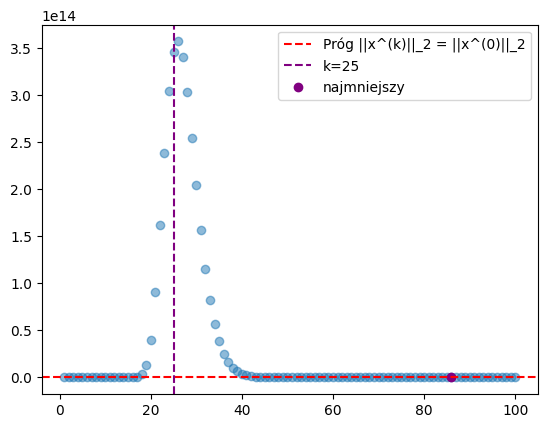

In [ ]:
# konstrukcja macierzy dwudiagonalnej
M = []
first_diagonal_value = 0.025
for i in range(20):
    temp = [0 for i in range(20)]
    temp[i] = first_diagonal_value + i * 0.025
    try: 
        temp[i+1]=5
    except:
        pass
    M.append(temp)

M = np.matrix(M)

# konstrukcja wektora x0
x0 = np.ones_like(temp, shape=(20,1))

eigenvalues, _ = np.linalg.eig(M)
if np.max(np.abs(eigenvalues)) < 1:
    print("spełniony jest warunek zbieżności metody iteracyjnej")
else: 
    print("nie spełniony")

# symulacja 
simulation_trials = 100
results = []
grid = np.arange(1, simulation_trials +1)
x0_norm = np.linalg.norm(x0)

x_i_temp = x0
for i in range(1,simulation_trials+1):
    x_i = M @ x_i_temp
    ni = np.linalg.norm(x_i) / x0_norm
    x_i_temp = x_i
    results.append(ni)

# szukamy najmniejszego k spełniającego warunek z zadania 
results = np.array(results) 
mask = results < 1
smallest_k = grid[mask][0]

# wykres
plt.scatter(grid, results, alpha=0.5)
plt.axhline(1, color='red', linestyle='--', label='Próg ||x^(k)||_2 = ||x^(0)||_2')
plt.axvline(25, color='purple', linestyle='--', label='k=25')
plt.scatter(smallest_k, results[smallest_k], color="purple", label="najmniejszy spełniający własność z zadania")
#plt.yscale('log')
plt.legend()
plt.show()
plt.close()
